# Using _egobox_ surrogate model _SparseGpx_

This tutorial is inspired from SGP tutorial from [SMT](https://github.com/SMTOrg/smt/tutorial).

## Installation

In [1]:
%pip install egobox

Note: you may need to restart the kernel to use updated packages.


We import _egobox_ as _egx_ for short

In [2]:
import egobox as egx

# Example 1 : SparseGpx basics

### Training 

#### Benchmark function definition

In [3]:
import numpy as np

def f_obj(x):
    return np.sin(3*np.pi*x) + 0.3*np.cos(9*np.pi*x) + 0.5*np.sin(7*np.pi*x)

#### Training data definition

In [4]:
# number of observations
N = 200

# noise
eta = 0.01

# Set seed via random generator for reproducibility
rng = np.random.RandomState(0)

# generate data
xt = 2*rng.rand(N, 1) - 1
yt = f_obj(xt) + rng.normal(loc=0.0, scale=np.sqrt(eta), size=(N,1))

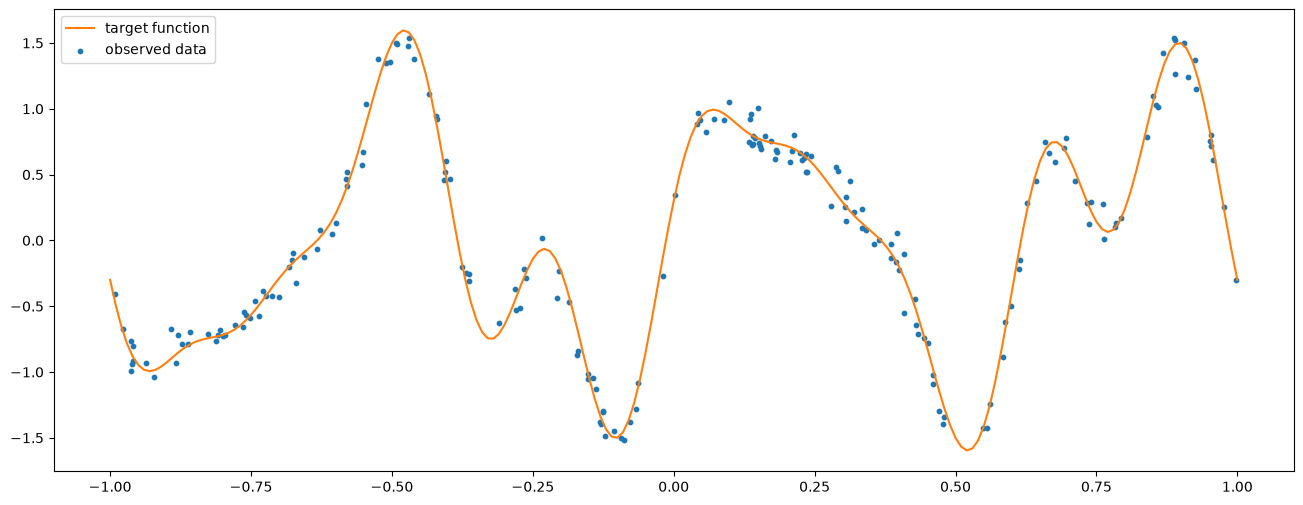

In [5]:
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 201).reshape(-1,1)
y = f_obj(x)

plt.figure(figsize=(16, 6))
plt.plot(x, y, "C1-", label="target function")
plt.scatter(xt, yt, marker="o", s=10, label="observed data")
plt.xlim([-1.1,1.1])
plt.legend(loc=0)
plt.show()

#### Building the surrogate

In order to ensure the proper convergence of optimization, we take an initial guess for theta based on the data std.\
Also, it can be useful to change the allowed bounds for this parameter.
    

In [6]:
# Initial guess for lengthscale parameter: standard deviation of training data
l = np.std(xt, axis=0)

# Transform to theta parameter (inverse of lengthscale)
theta0 = 1/l**2
print("theta0 :", theta0)

# Specify bounds for theta
bounds = [[1e-8, 1e2]] 

theta0 : [3.10146663]


In [7]:
sgpx = egx.SparseGpx.builder(theta_init=theta0, theta_bounds=bounds, n_inducing=30, seed=42).fit(xt, yt)

# Print trained surrogate
print(sgpx)
print(sgpx.thetas)
print(sgpx.variances)
print(sgpx.likelihoods)

Mixture[Smooth(1)](SquaredExponentialSGP(corr=SquaredExponential, theta=[8.620922857515069], variance=2.247260174322624, noise variance=0.008882496000352652, likelihood=284.8767621357074))
[[8.62092286]]
[2.24726017]
[284.87676214]


### Prediction

#### Using the surrogate for estimation

In [8]:
hat_y = sgpx.predict(x)
var = sgpx.predict_var(x)
d_hat_y = sgpx.predict_gradients(x)
d_var = sgpx.predict_var_gradients(x)

#### Plotting results

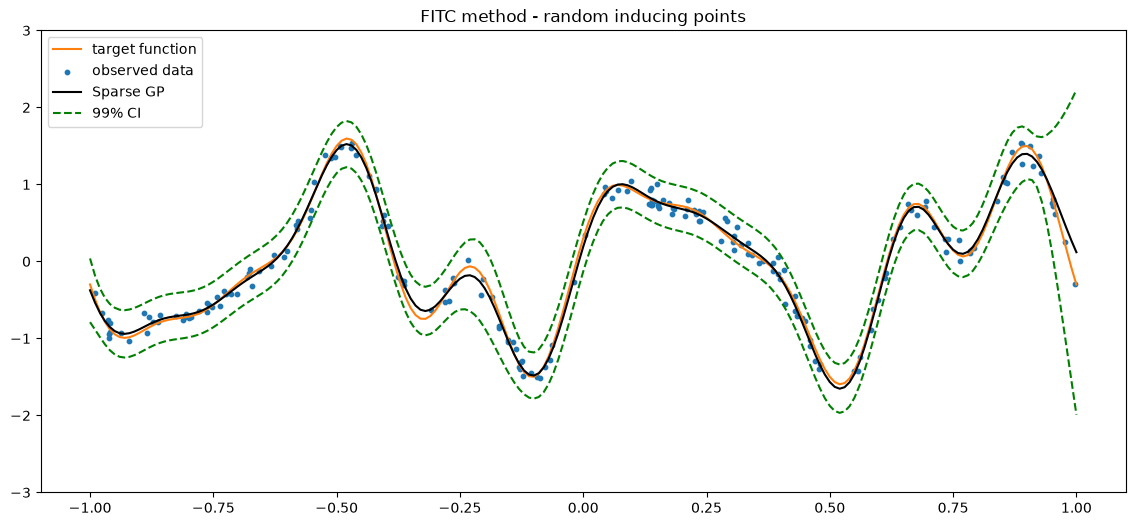

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(x, y, "C1-", label="target function")
plt.scatter(xt, yt, marker="o", s=10, label="observed data")
plt.plot(x, hat_y, "k-", label="Sparse GP")

plt.plot(x, hat_y - 3 * np.ravel(np.sqrt(var)), "g--")
plt.plot(x, hat_y + 3 * np.ravel(np.sqrt(var)), "g--", label="99% CI")
#plt.plot(Z1, -2.9 * np.ones_like(Z1), "r|", mew=2, label="inducing points - random")
plt.ylim([-3, 3])
plt.legend(loc=0)
plt.title('FITC method - random inducing points')
plt.show()

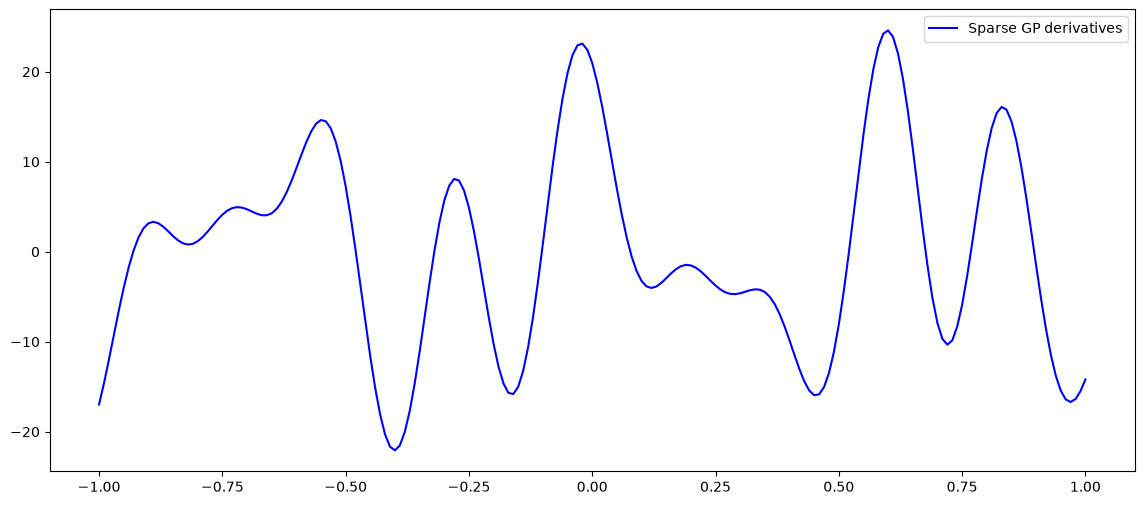

In [10]:
plt.figure(figsize=(14, 6))
plt.plot(x, d_hat_y, "b-", label="Sparse GP derivatives")
plt.legend(loc=0)
#plt.plot(x, var, "r.", label="Sparse GP")
#plt.plot(x, d_var, "r-", label="Sparse GP")

#### Sampling the conditionned Full Gaussian Process


In [11]:
# number fo trajectories to sample
n_traj = 30

trajs = sgpx.sample(x, n_traj)

#### Plotting trajectories

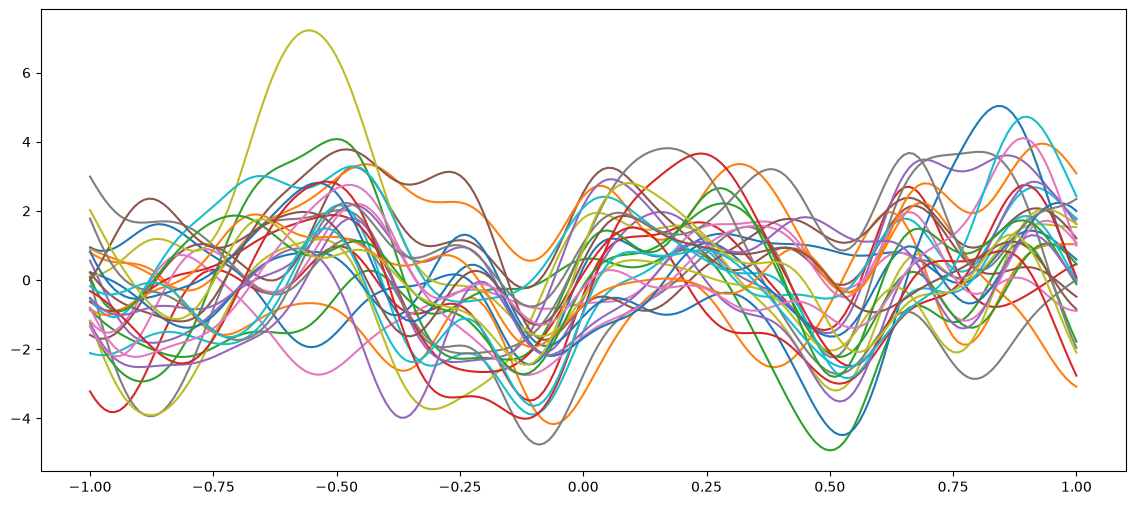

In [12]:
fig, axs = plt.subplots(1,figsize=(14, 6))

for i in range(n_traj):
    axs.plot(x, trajs[:, i])

plt.show()

## SparseGpx API

In [13]:
help(egx.SparseGpx.builder())

Help on SparseGpMix in module egobox object:

class SparseGpMix(builtins.object)
 |  SparseGpMix(corr_spec=Ellipsis, theta_init=None, theta_bounds=None, kpls_dim=None, theta_n_start=Ellipsis, n_inducing=None, inducing=None, method=Ellipsis, seed=None, verbose=None)
 |
 |  Sparse Gaussian process builder
 |
 |  Inducing points are required: give either their number `n_inducing` or their locations `inducing`.
 |
 |  Parameters
 |  ----------
 |  corr_spec : int
 |      CorrelationSpec flags, an int in [1, 15]. Specification of correlation models.
 |      Can be CorrelationSpec.SQUARED_EXPONENTIAL (1), CorrelationSpec.ABSOLUTE_EXPONENTIAL (2),
 |      CorrelationSpec.MATERN32 (4), CorrelationSpec.MATERN52 (8) or
 |      any bit-wise union of these values (e.g. CorrelationSpec.MATERN32 | CorrelationSpec.MATERN52)
 |  theta_init : list of float, optional
 |      Initial guess for GP theta hyperparameters, one value per input component.
 |      When None the default is 1e-1 for all component

In [14]:
help(egx.SparseGpx)

Help on class SparseGpx in module egobox:

class SparseGpx(builtins.object)
 |  A trained sparse Gaussian process
 |
 |  Unlike `Gpx`, it has no `update` method: sparse GPs have to be refitted with the new data.
 |
 |  Methods defined here:
 |
 |  __repr__(self, /)
 |      Return repr(self).
 |
 |  __str__(self, /)
 |      Return str(self).
 |
 |  dims(self, /)
 |      Get the input and output dimensions of the surrogate
 |
 |      Returns
 |      -------
 |      tuple[int, int]
 |          the couple (nx, ny)
 |
 |  predict(self, /, x, return_std=False)
 |      Predict output values at nsamples points.
 |
 |      Parameters
 |      ----------
 |      x : array[nsamples, nx] or array[nsamples] when nx == 1
 |          input values
 |      return_std : bool
 |          When True, the standard deviations of the predictions are also returned,
 |          computed as sqrt(predict_var(x)) (default is False)
 |
 |      Returns
 |      -------
 |      array[nsamples] or (array[nsamples], arra